In [1]:
from Functions import *
from Rewiring_functions import *

In [2]:
Ilist=read_database()
#create a dictionary with the matrix of each site-eachyear
networks={}
for site in Sites:
    #print(site)
    networks[site]={}
    for year in Years:
        Imat = Ilist.xs((site,year),level=["Site_ID", "Year"]).pivot(index="Plant_gen_sp",columns="Pollinator_gen_sp",values="Frequency").fillna(0)
        networks[site][year]=Imat


In [3]:
#Lets choose a site, and year to plot!
site=Sites[0] #2
year=Years[0]#4
web1=networks[site][year]
web2=networks[site][year+1]

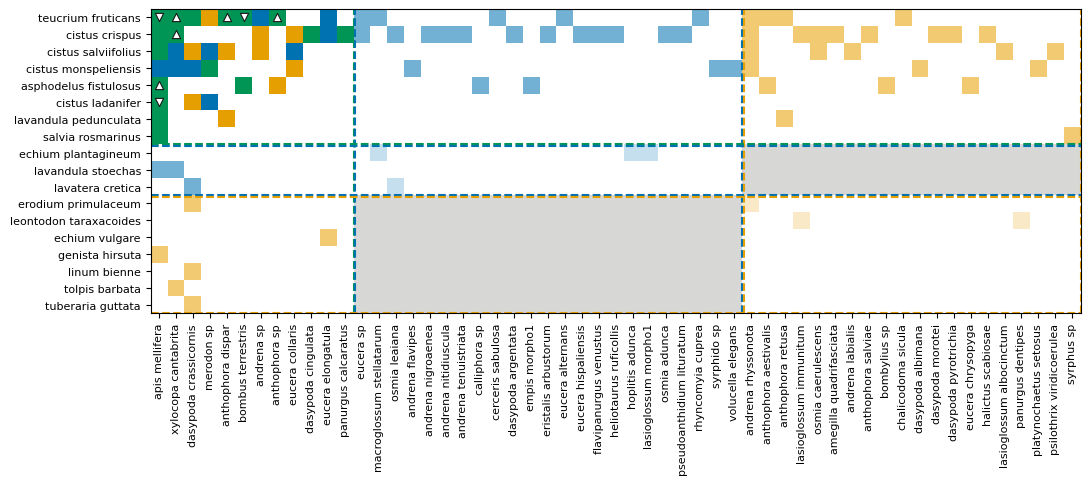

In [4]:
#The networks shown in figure 1 is generated like this: not weighted still looks if there are links taht increase in strength (if valeus are 1 this is 0 by default)
plt.rcParams.update({'font.size': 15})
# Create a figure
fig, ax1 = plt.subplots(figsize=(12, 8))
plot_betadiversity_Wmatrix_to_ax3(web1,web2,ax=ax1,weighted=False,names=True)
plt.show()

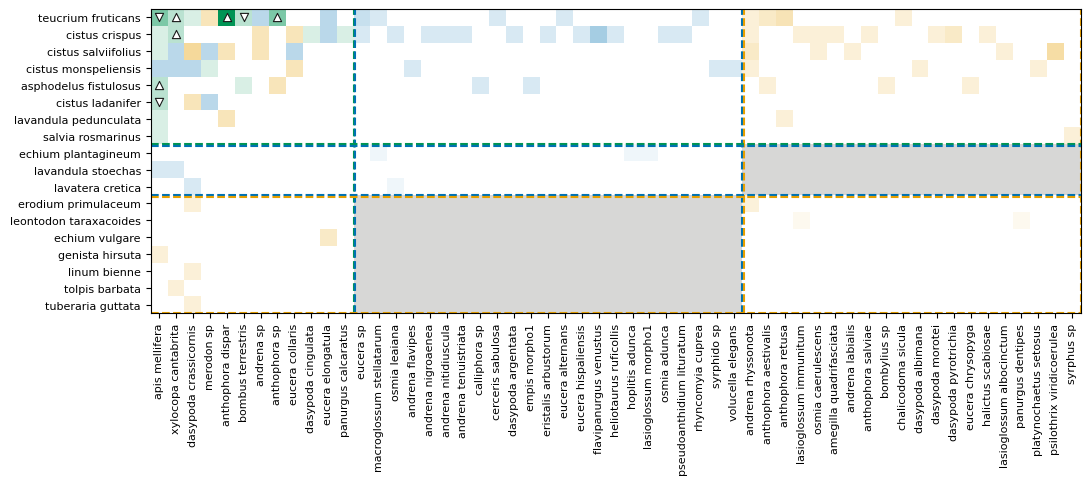

In [5]:
#in the weighted version, one can see the frequecny of change, not only the mechanisms (not shown in main text)
fig, ax1 = plt.subplots(figsize=(12, 8))
plot_betadiversity_Wmatrix_to_ax3(web1,web2,ax=ax1,names=True)
plt.show()

# quantification of changes

In [6]:
# We store the databases with 1 to 4 time lag
#create dictionaries with the 4 time lags
metric=['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
metric_N=["PA","PP","A1","P1","A2","P2"]
mi2=pd.MultiIndex.from_product([Sites,Years[1::],metric],names=["Site_ID", "year","metric"])
mi2N=pd.MultiIndex.from_product([Sites,Years[1::],metric_N],names=["Site_ID", "year","metric"])
All_Changes={}
All_Nodes={}
for N in range(1,5):
    Changes_df=pd.DataFrame(index=mi2,columns=["n_interactions","freq_interactions"])
    Changes_df.sort_index(inplace=True)
    
    Nodes_df=pd.DataFrame(index=mi2N,columns=["n_nodes"])
    Nodes_df.sort_index(inplace=True)
    
    for site in Sites:
        for year in Years[0:-N]:
            changes, nodes = rewiring_freq_py(networks[site][year], networks[site][year+N])
            changes = changes.set_index('metric')          # <- AÑADIR esto
            nodes = nodes.set_index('metric')          # <- AÑADIR esto
            for m in changes.index:                        # <- 'm', NO 'metric'
                Changes_df.loc[(site, year+N, m), 'n_interactions'] = changes.loc[m, 'n_interactions']
                Changes_df.loc[(site, year+N, m), 'freq_interactions'] = changes.loc[m, 'freq_sum']
            for m in nodes.index:                        # <- 'm', NO 'metric'
                Nodes_df.loc[(site, year+N, m), 'n_nodes'] = nodes.loc[m, 'n_species']
        Changes_df['n_interactions'] = Changes_df['n_interactions'].astype('float64')
        Changes_df['freq_interactions'] = Changes_df['freq_interactions'].astype('float64')
    All_Changes[N]=Changes_df
    All_Nodes[N]=Nodes_df
  

# Average descritpion trough time, for one site

In [7]:
#we focuss in the main on time lag 1
Changes_df=All_Changes[1]
Nodes_df=All_Nodes[1]

/home/gato/ownCloud/Trabajo/colaboraciones/Rewiring Alfonso/Rwiring_manuscript_code/Functions.py:2318: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


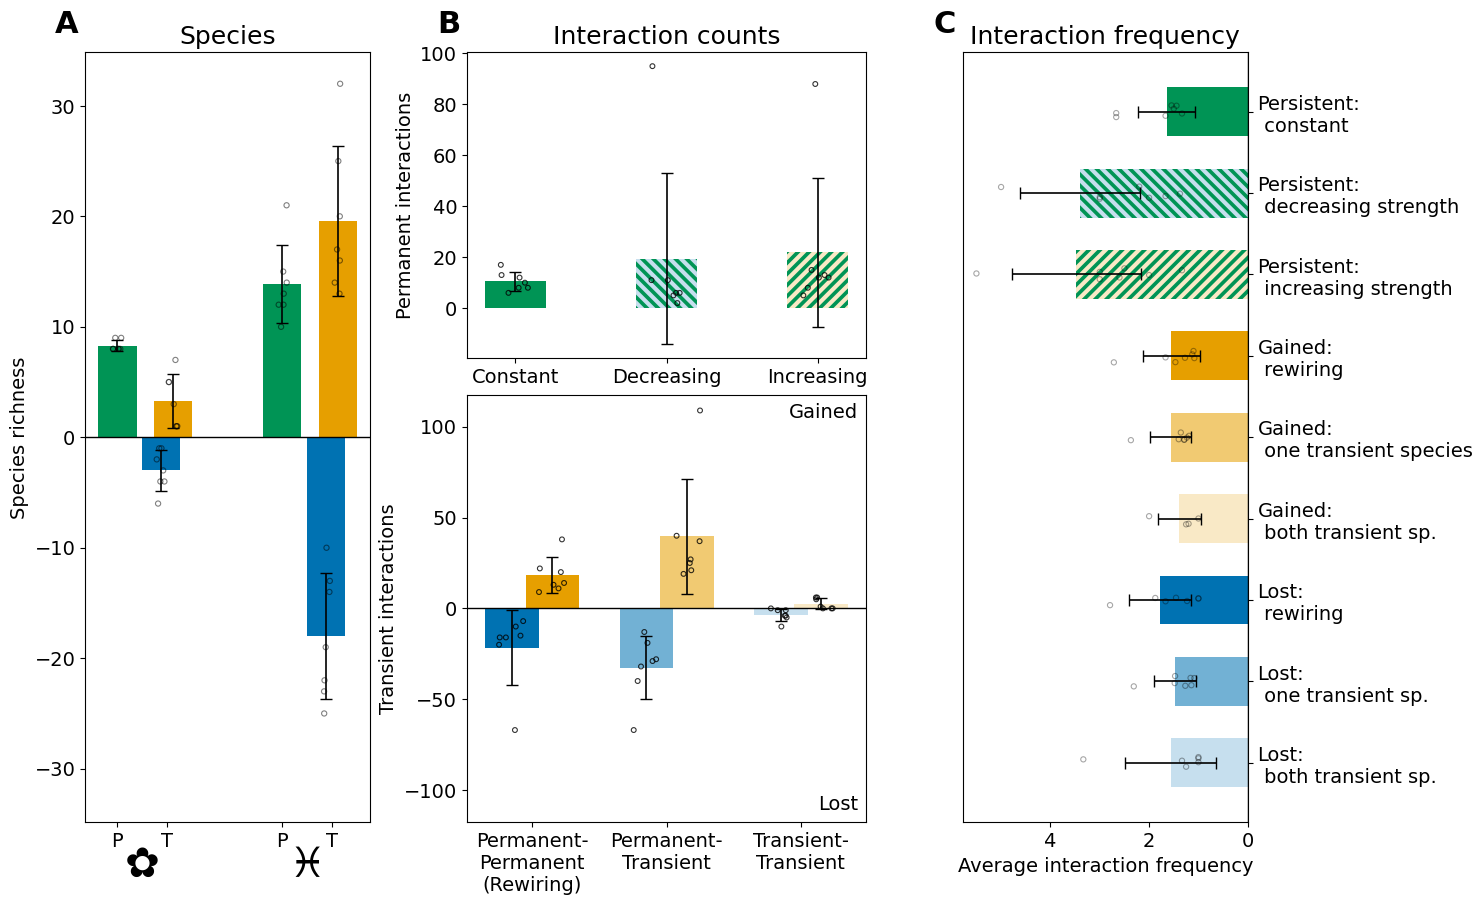

In [8]:
site=Sites[0] #we also only focuss in one site during the main manuscript, so choose one
fig, (ax_species, ax_int_top, ax_int_bottom, ax_freq) = plot_species_and_interactions_summary(
    Nodes_df.loc[site],   # tu tabla de especies, filtrada al sitio
    Changes_df.loc[site],        # tu tabla de interacciones, filtrada al sitio
    figsize=(15, 10),
    species_kwargs={'value_col': 'n_nodes'},
    interactions_kwargs={'value_col': 'freq_interactions'},
    frequency_kwargs={'freq_col': 'freq_interactions', 'n_col': 'n_interactions'}
)
plt.savefig("./FIGURES/BeeFun/Figure_3.png", dpi=150, bbox_inches='tight')

In [9]:
#perform the significance test for that site
kw_result, posthoc_df, latex_table = test_interaction_frequency_differences2(Changes_df, label_dict=label_dict2)
with open("./FIGURES/BeeFun/Table_S11.tex", "w") as f:
    f.write(latex_table)

Kruskal-Wallis: H=91.138, p=0.0000 (SIGNIFICATIVO a alpha=0.05)

Post-hoc de Dunn (p-valores, correccion holm):
         CN_CI   CN_DI   CN_II   CN_LI   CN_GI  L1N_LI  LBN_LI  G1N_GI  GBN_GI
CN_CI   1.0000  0.0001  0.0004  1.0000  1.0000  1.0000  0.6844  1.0000  1.0000
CN_DI   0.0001  1.0000  1.0000  0.0001  0.0001  0.0000  0.0000  0.0001  0.0000
CN_II   0.0004  1.0000  1.0000  0.0006  0.0005  0.0000  0.0000  0.0006  0.0000
CN_LI   1.0000  0.0001  0.0006  1.0000  1.0000  1.0000  0.3898  1.0000  0.7608
CN_GI   1.0000  0.0001  0.0005  1.0000  1.0000  1.0000  0.3060  1.0000  0.6804
L1N_LI  1.0000  0.0000  0.0000  1.0000  1.0000  1.0000  0.9343  1.0000  1.0000
LBN_LI  0.6844  0.0000  0.0000  0.3898  0.3060  0.9343  1.0000  0.2371  1.0000
G1N_GI  1.0000  0.0001  0.0006  1.0000  1.0000  1.0000  0.2371  1.0000  0.5584
GBN_GI  1.0000  0.0000  0.0000  0.7608  0.6804  1.0000  1.0000  0.5584  1.0000

Tabla LaTeX:
\begin{table}[ht]
\centering
\begin{tabular}{lccccccccc}
\toprule
 & CN_CI & CN_DI &

In [10]:
Changes_df.loc[site].reset_index().groupby("metric").mean(numeric_only=True)

,year,n_interactions,freq_interactions
metric,,,
CN_CI,2019.0,6.428571,10.571429
CN_DI,2019.0,5.714286,19.428571
CN_GI,2019.0,11.714286,18.142857
CN_II,2019.0,6.285714,21.857143
CN_LI,2019.0,12.142857,21.571429
G1N_GI,2019.0,25.428571,39.714286
GBN_GI,2019.0,1.857143,2.571429
L1N_LI,2019.0,22.142857,32.571429
LBN_LI,2019.0,2.285714,3.571429


# detail in time, for one site

/home/gato/ownCloud/Trabajo/colaboraciones/Rewiring Alfonso/Rwiring_manuscript_code/Functions.py:1462: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


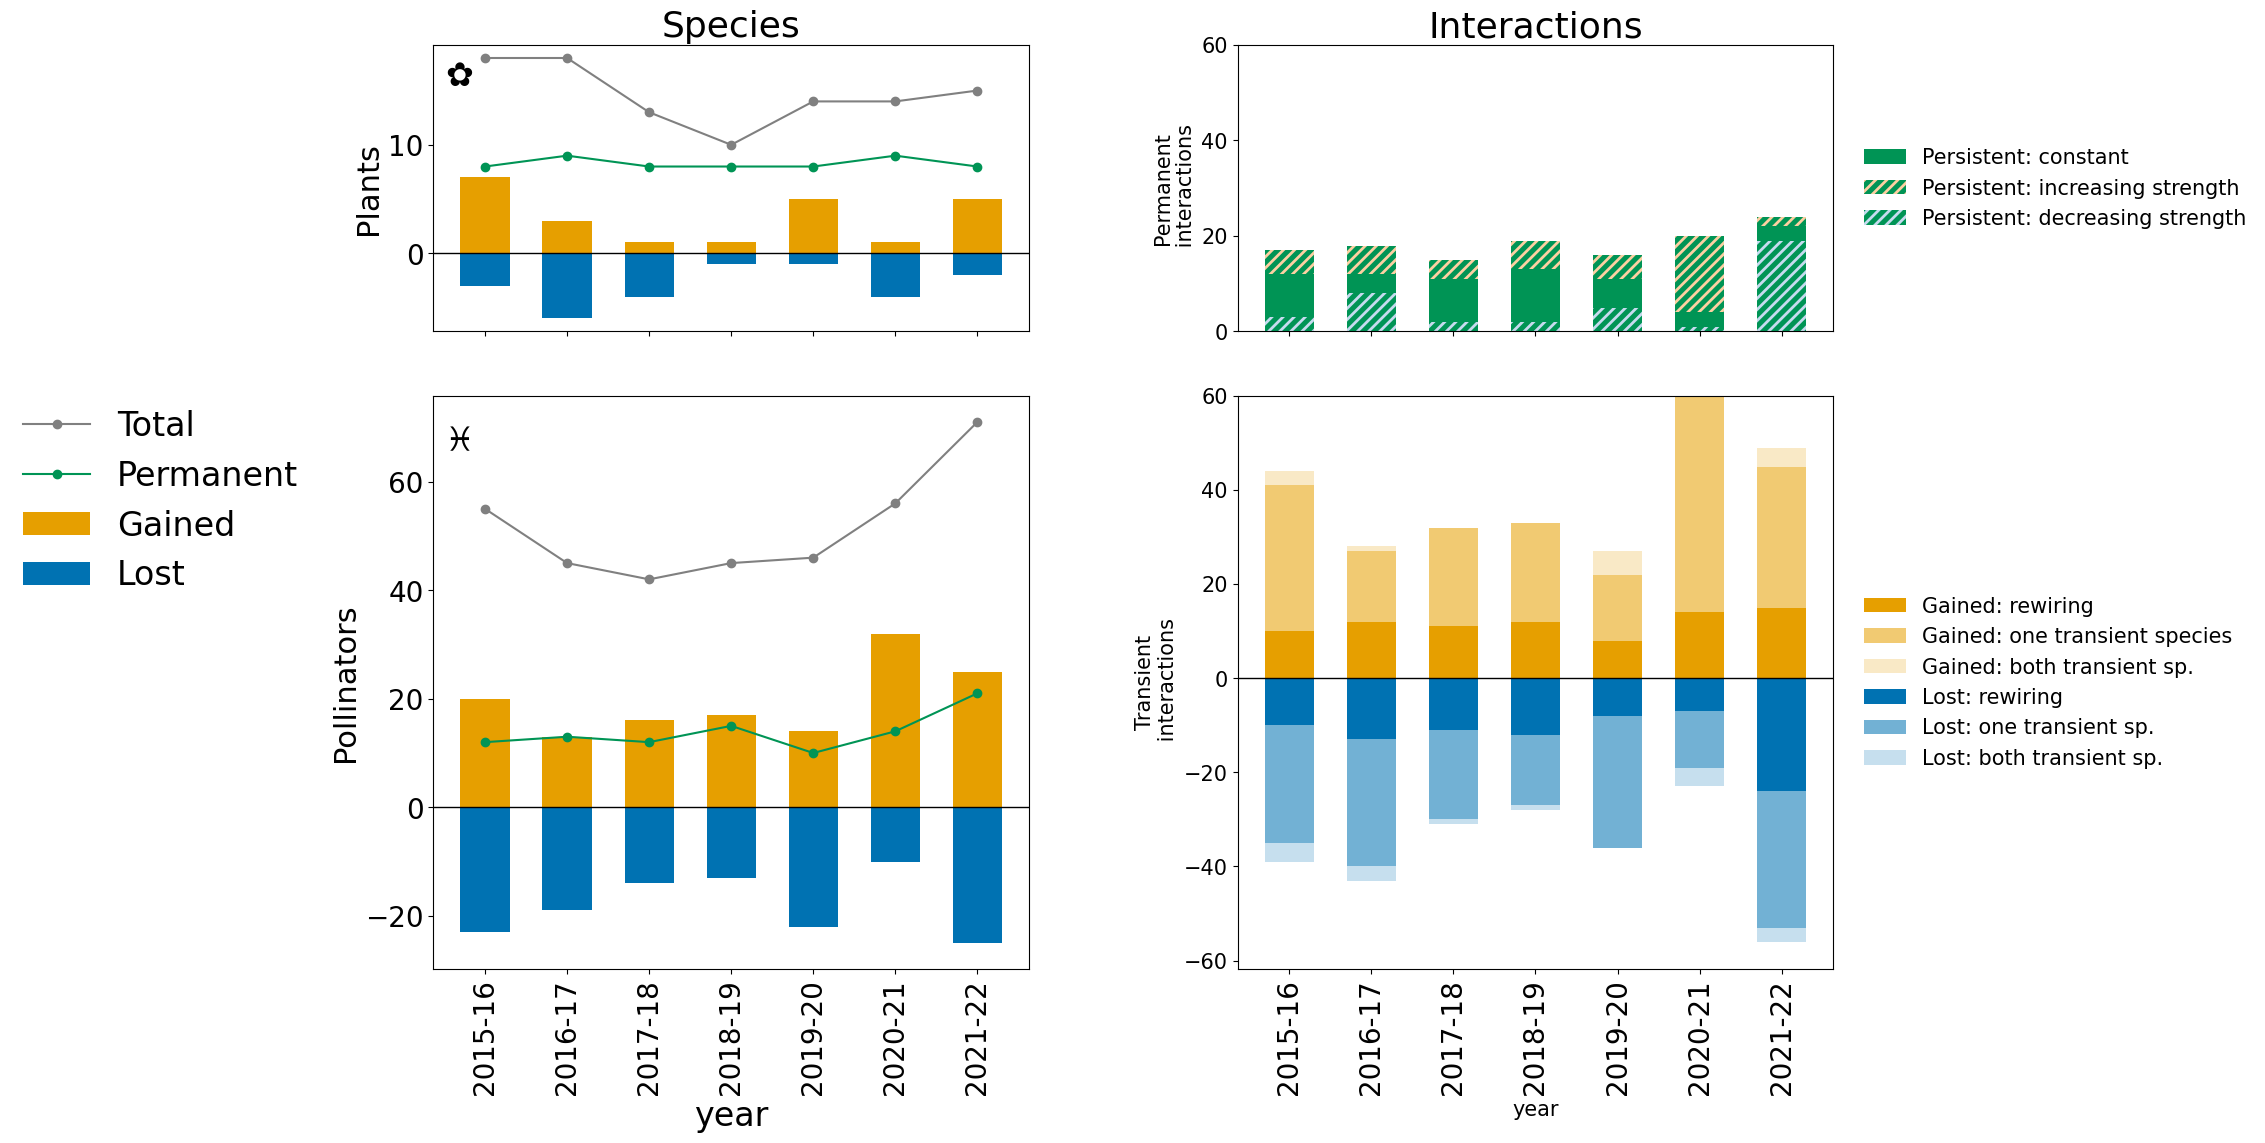

In [11]:
# If we look in deatil one site . However we plot all sites toghether in the supp, see below
fig, (ax_plants, ax_poll, ax_top, ax_bottom) = plot_species_and_turnover_summary(
    Nodes_df.loc[site],        # species 
    Changes_df.loc[site], # Changes_df del sitio
)
plt.show()

## Detail in time for all sites

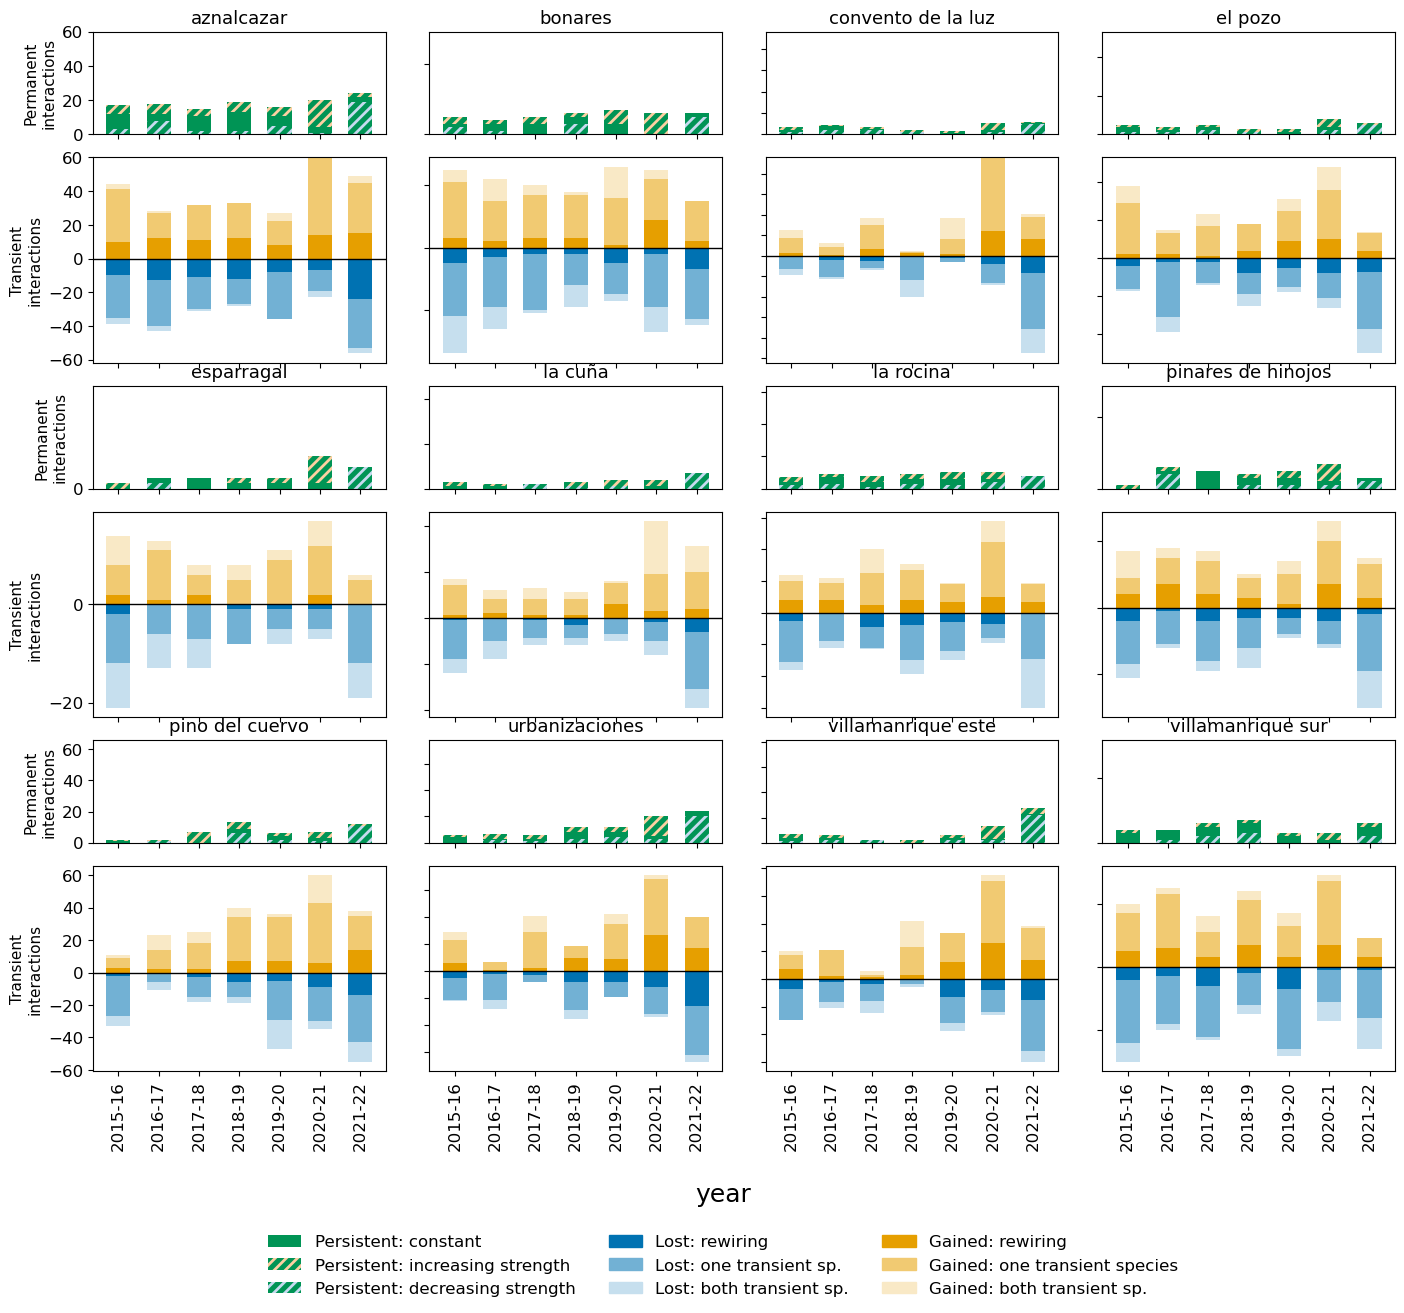

In [12]:
fig, site_axes = plot_diverging_bars_with_constant_all_sites(Changes_df, value_col='n_interactions', sharey=False, year_label_dict=year_label_dict, label_dict=label_dict)
filename="./FIGURES/BeeFun/Fig_S7.png"
plt.savefig(filename, dpi=150, bbox_inches='tight')
plt.show()

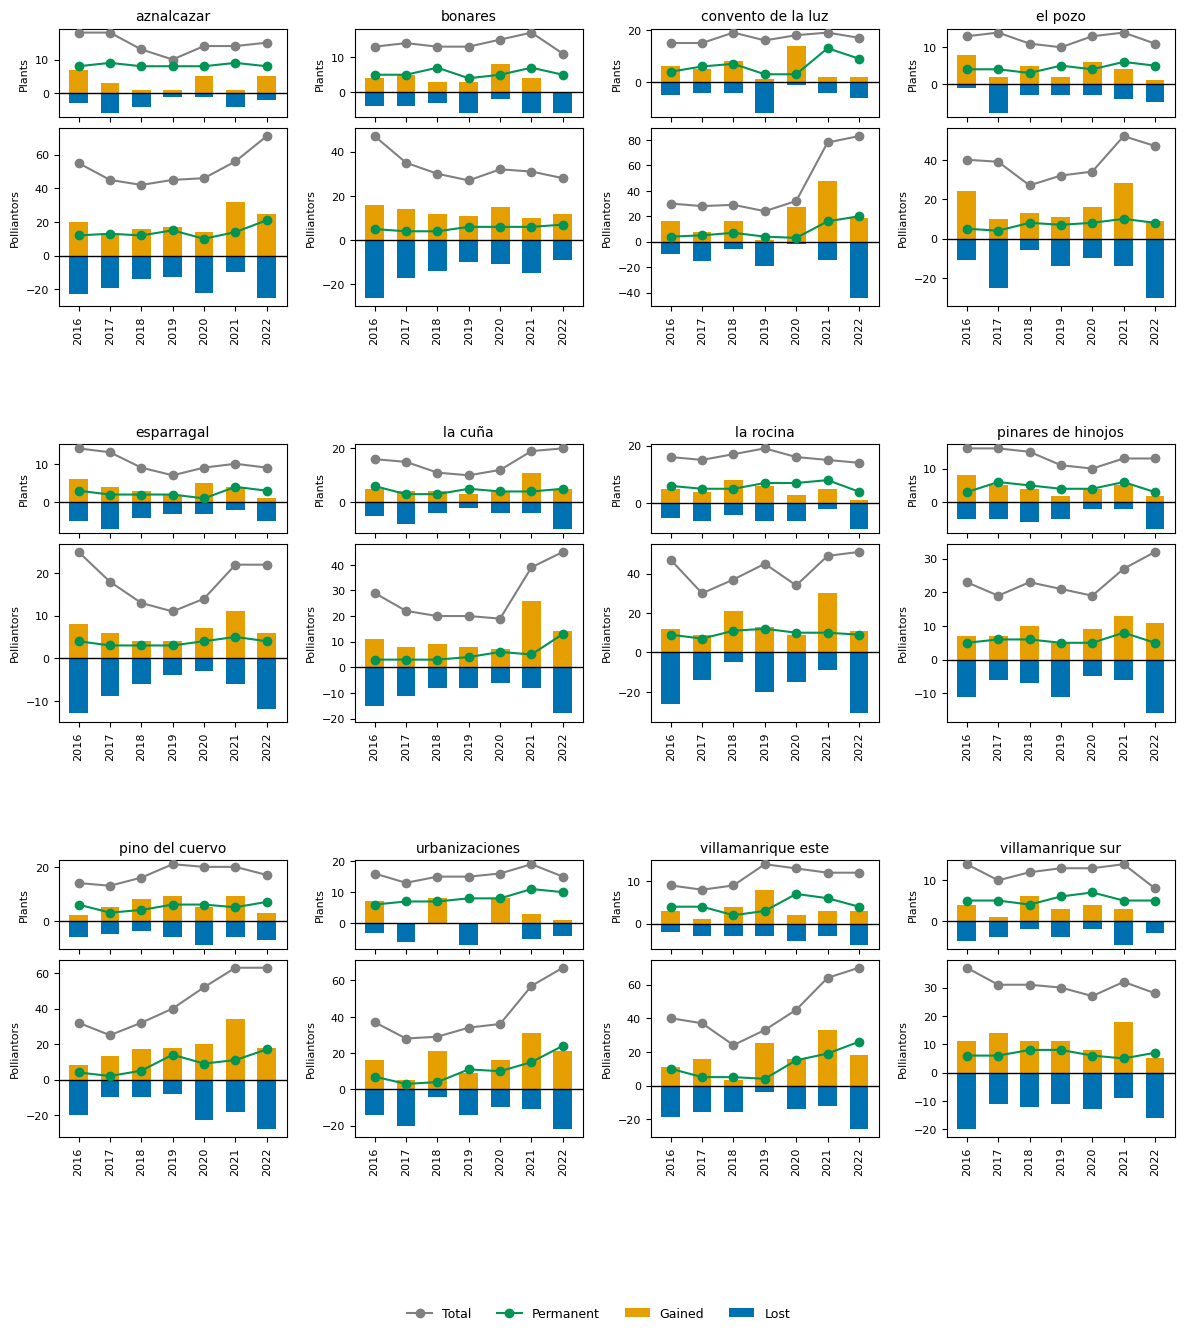

In [13]:
fig, site_axes = plot_species_turnover_all_sites(Nodes_df)
plt.savefig("./FIGURES/BeeFun/Fig_S6.png", dpi=150, bbox_inches='tight')

# Aggregated over time for all sites

/home/gato/ownCloud/Trabajo/colaboraciones/Rewiring Alfonso/Rwiring_manuscript_code/Functions.py:2318: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


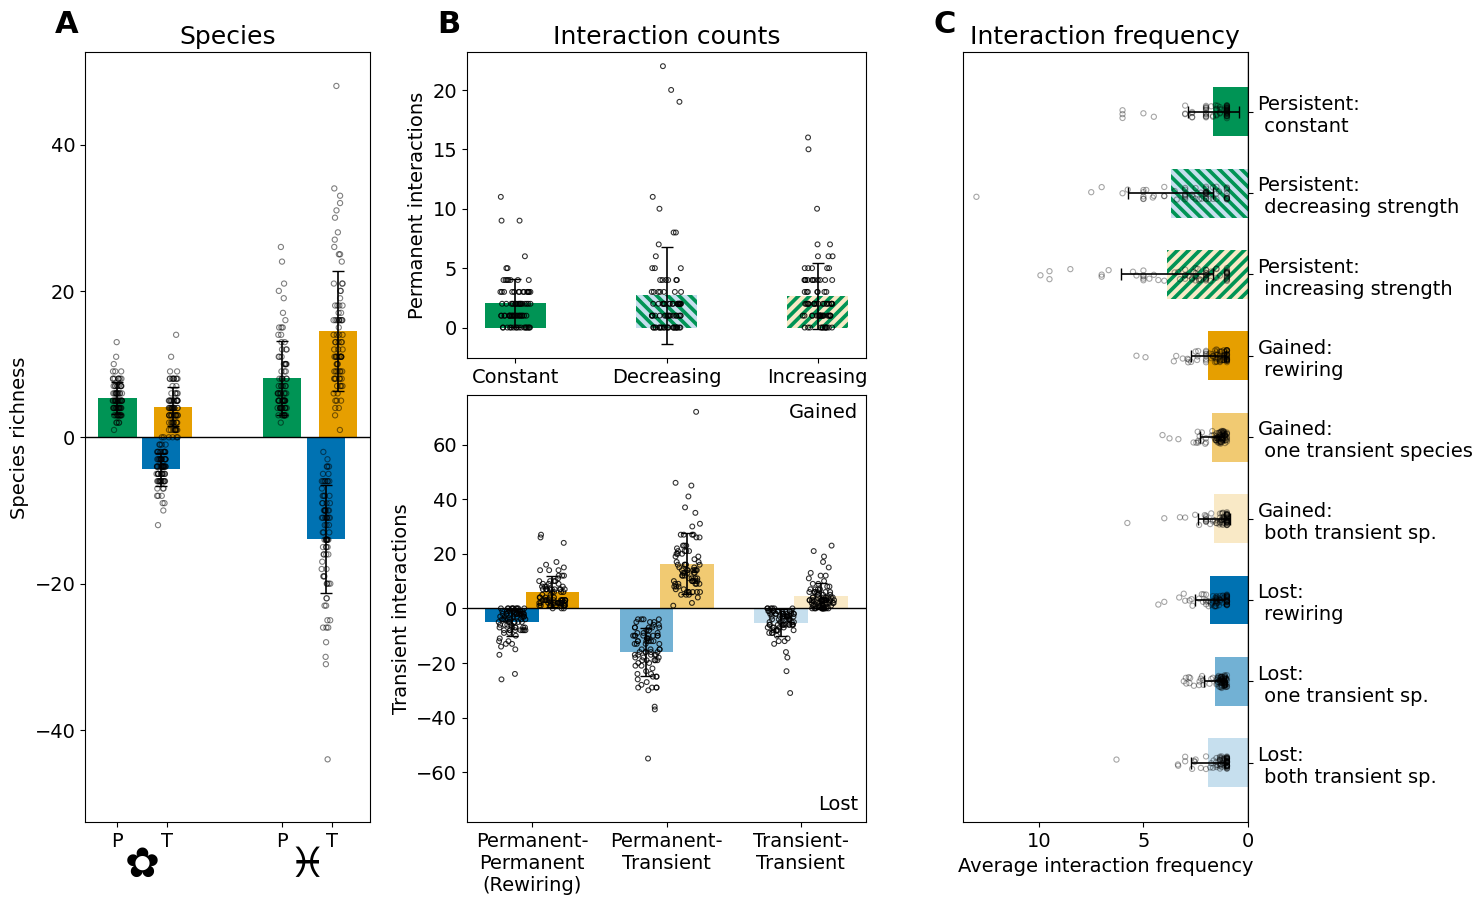

In [14]:
#lets find the general trend, as shown in the supplementary
fig, (ax_species, ax_int_top, ax_int_bottom, ax_freq) = plot_species_and_interactions_summary(
    Nodes_df,#.loc[site],   # tu tabla de especies, filtrada al sitio
    Changes_df,#.loc[site],        # tu tabla de interacciones, filtrada al sitio
    figsize=(15, 10),
    species_kwargs={'value_col': 'n_nodes'},
    interactions_kwargs={'value_col': 'n_interactions'},
    frequency_kwargs={'freq_col': 'freq_interactions', 'n_col': 'n_interactions'}
)
plt.savefig("./FIGURES/BeeFun/Fig_S8.png", dpi=150, bbox_inches='tight')

# Temporality
Lets see how results change if we take lag t+2, t+3 or t+4


In [15]:
#We use the same dictionaries to store
All_Changes={}
All_Nodes={}
for N in range(1,5):
    Changes_df=pd.DataFrame(index=mi2,columns=["n_interactions","freq_interactions"])
    Changes_df.sort_index(inplace=True)
    
    Nodes_df=pd.DataFrame(index=mi2N,columns=["n_nodes"])
    Nodes_df.sort_index(inplace=True)
    
    for site in Sites:
        for year in Years[0:-N]:
            changes, nodes = rewiring_freq_py(networks[site][year], networks[site][year+N])
            changes = changes.set_index('metric')          # <- AÑADIR esto
            nodes = nodes.set_index('metric')          # <- AÑADIR esto
            for m in changes.index:                        # <- 'm', NO 'metric'
                Changes_df.loc[(site, year+N, m), 'n_interactions'] = changes.loc[m, 'n_interactions']
                Changes_df.loc[(site, year+N, m), 'freq_interactions'] = changes.loc[m, 'freq_sum']
            for m in nodes.index:                        # <- 'm', NO 'metric'
                Nodes_df.loc[(site, year+N, m), 'n_nodes'] = nodes.loc[m, 'n_species']

    All_Changes[N]=Changes_df
    All_Nodes[N]=Nodes_df
  

## one site

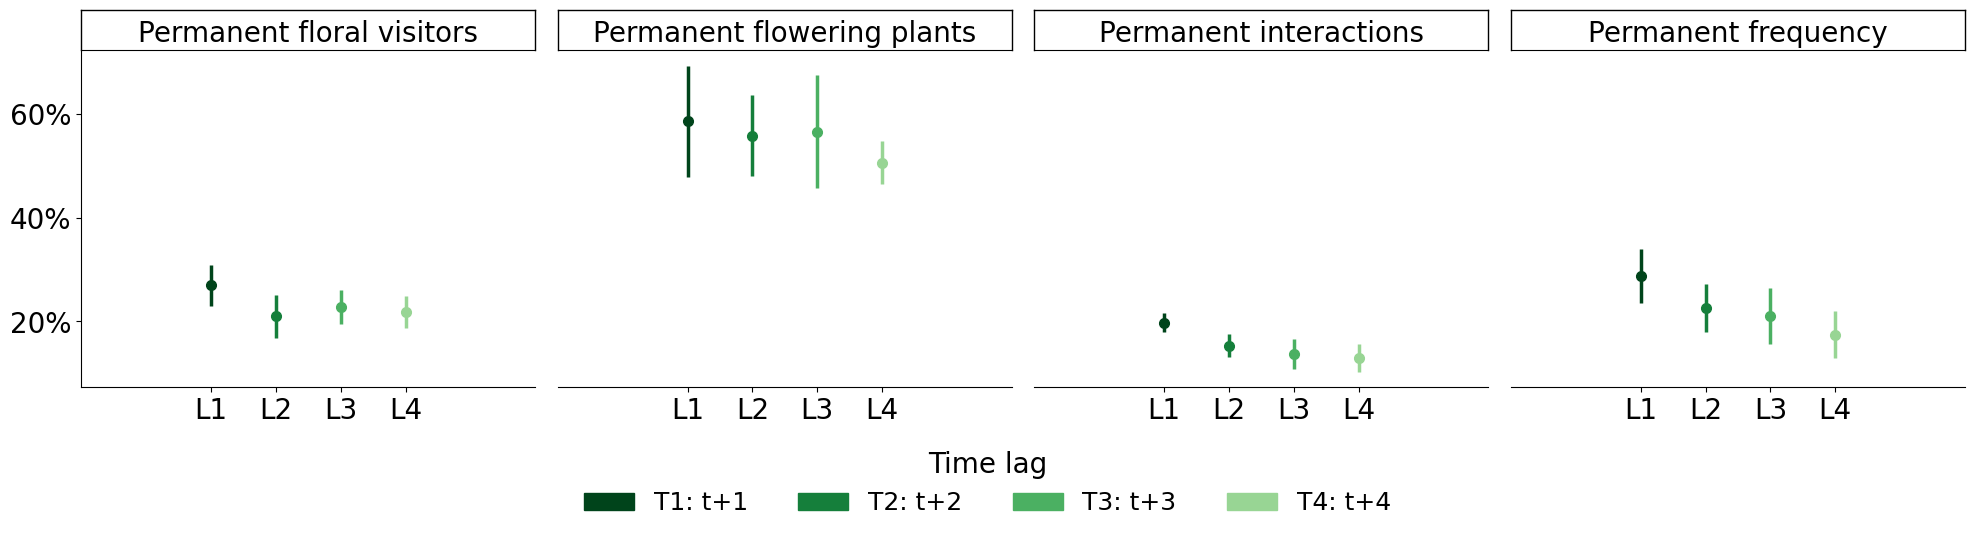

In [16]:
#explore the chosen site, for the main text
fig, axes, summary_df = plot_lag_summary_temporal(All_Nodes, All_Changes, site=Sites[0])
plt.savefig("./FIGURES/BeeFun/Figure_3B.png", dpi=150, bbox_inches='tight')

## All sites

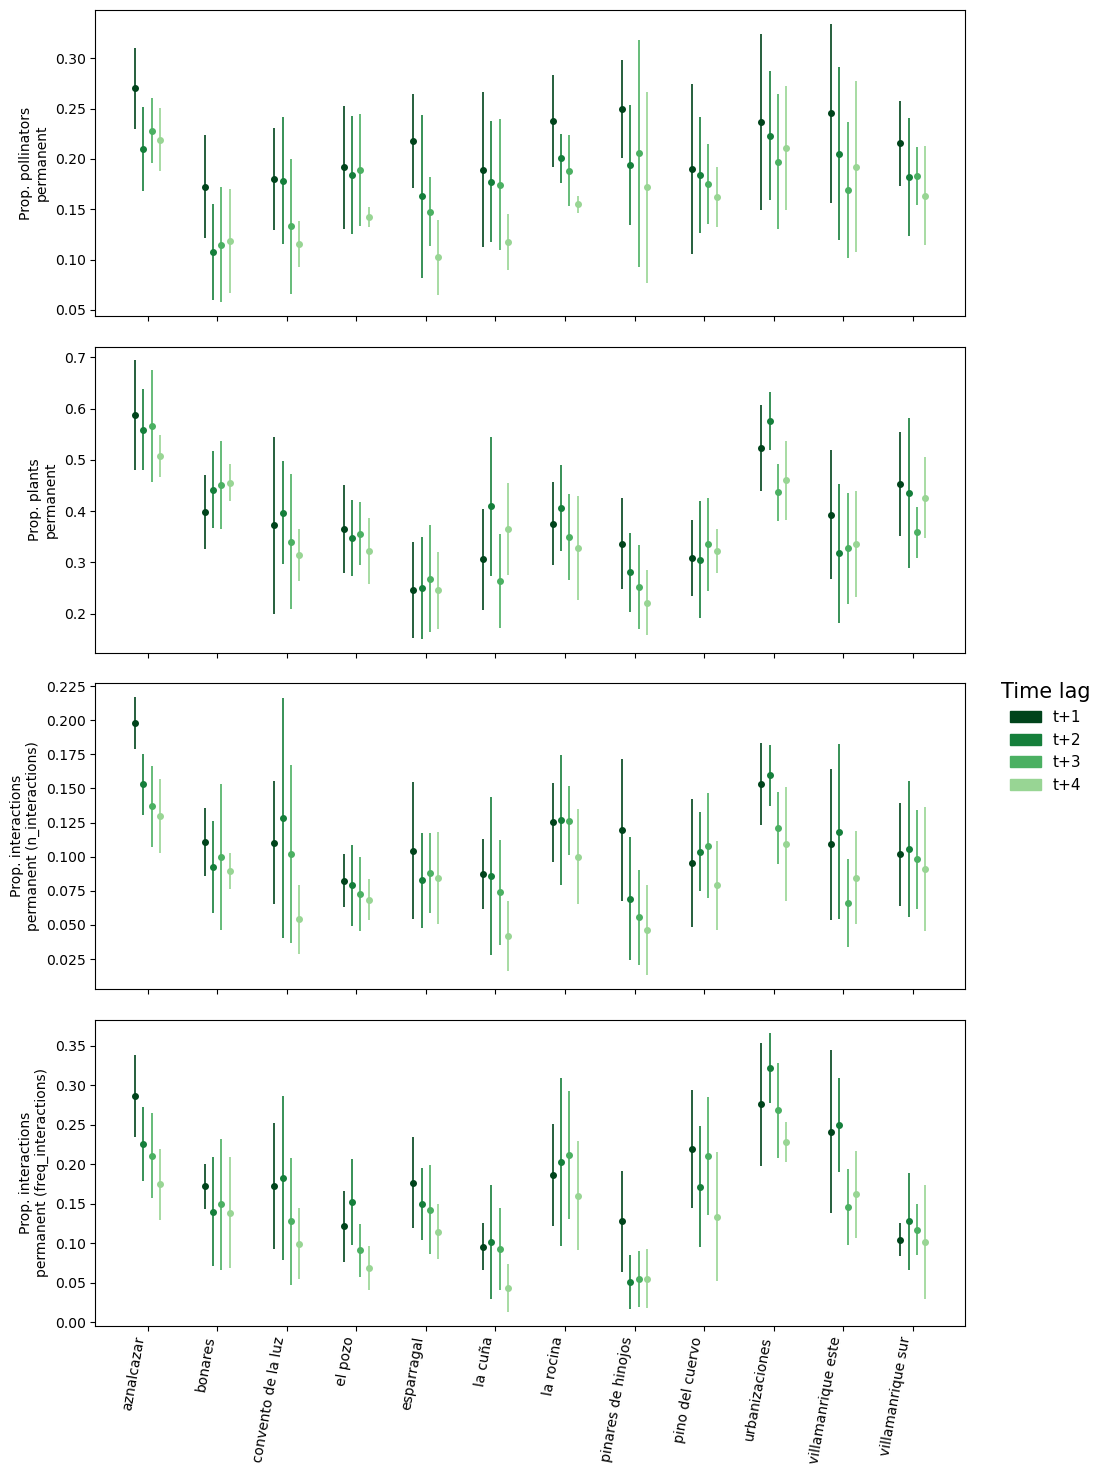

In [ ]:
#or all sites, for the supp
fig, axes, extra_data = plot_lag_summary_combined_vertical(All_Nodes, All_Changes,sharey=False, offset=0.12)
plt.savefig("./FIGURES/BeeFun/Fig_S9.pdf", dpi=150, bbox_inches='tight')